# HW1: python data analysis basics

You will be working with data on the counts of bicycles crossing the Fremont Bridge since 2012 (as described in https://data.seattle.gov/Transportation/Fremont-Bridge-Hourly-Bicycle-Counts-by-Month-Octo/65db-xm6k).

## 0. Import Packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Read the CSV file into a pandas dataframe. (1pt)

In [2]:
df = pd.read_csv('./bicycle_data.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122675 entries, 0 to 122674
Data columns (total 4 columns):
 #   Column                                                              Non-Null Count   Dtype  
---  ------                                                              --------------   -----  
 0   Date                                                                122675 non-null  object 
 1   Fremont Bridge Sidewalks, south of N 34th St Total                  122645 non-null  float64
 2   Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk  122645 non-null  float64
 3   Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk  122645 non-null  float64
dtypes: float64(3), object(1)
memory usage: 3.7+ MB


NOTE: contains missing values! (probably NaNs)

## 2. In a comment, describe the columns in the dataframe and what data types they should be. If the data types in the dataframe do not match what you think they should be, update them. (1pt)

| Column Name | Description | Data Type |
| ------- | ----------- | ----- |
| Date | Date and time in MM/DD/YYYY HH:MM:SS format | datetime |
| Fremont Bridge Sidewalks, south of N 34th St Total | Total count of bikes south of N 34th St | int |
| Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk | Count of bikes south of N 34th St on the west sidewalk | int |
| Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk | Count of bikes south of N 34th St on the east sidewalk | int |

Data types do not match what I think they should be.

In [3]:
df['Date'][0]

'10/02/2012 01:00:00 PM'

In [4]:
df.columns

Index(['Date', 'Fremont Bridge Sidewalks, south of N 34th St Total',
       'Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk',
       'Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk'],
      dtype='object')

In [ ]:
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y %I:%M:%S %p')

# based on https://medium.com/analytics-vidhya/pandas-part-two-2973075d6484
df = df.astype({
    'Fremont Bridge Sidewalks, south of N 34th St Total': 'Int64',
    'Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk': 'Int64',
    'Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk': 'Int64'
})
# NOTE: Int64 handles NaNs, but np.int64 does not

df.head()

,Date,"Fremont Bridge Sidewalks, south of N 34th St Total","Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk"
0,2012-10-02 13:00:00,55,48,7
1,2012-10-02 14:00:00,130,75,55
2,2012-10-02 15:00:00,152,71,81
3,2012-10-02 16:00:00,278,111,167
4,2012-10-02 17:00:00,563,170,393


## 3. Add columns to the dataframe containing:
- The total (East + West) bicycle count. (1pt)
- The hour of the day. (1pt)
- The year. (1pt)

In [6]:
df['total'] = df['Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk'] + df['Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk']
df['hour'] = df['Date'].dt.hour
df['Year'] = df['Date'].dt.year

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122675 entries, 0 to 122674
Data columns (total 7 columns):
 #   Column                                                              Non-Null Count   Dtype         
---  ------                                                              --------------   -----         
 0   Date                                                                122675 non-null  datetime64[ns]
 1   Fremont Bridge Sidewalks, south of N 34th St Total                  122645 non-null  Int64         
 2   Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk  122645 non-null  Int64         
 3   Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk  122645 non-null  Int64         
 4   total                                                               122645 non-null  Int64         
 5   hour                                                                122675 non-null  int32         
 6   Year                                         

In [7]:
df.head()

,Date,"Fremont Bridge Sidewalks, south of N 34th St Total","Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk",total,hour,Year
0,2012-10-02 13:00:00,55,48,7,55,13,2012
1,2012-10-02 14:00:00,130,75,55,130,14,2012
2,2012-10-02 15:00:00,152,71,81,152,15,2012
3,2012-10-02 16:00:00,278,111,167,278,16,2012
4,2012-10-02 17:00:00,563,170,393,563,17,2012


## 4. Create a new dataframe with the subset of data from the year 2016. (1pt)

In [8]:
df_2016 = df[df['Year'] == 2016]
df_2016.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8784 entries, 28451 to 37234
Data columns (total 7 columns):
 #   Column                                                              Non-Null Count  Dtype         
---  ------                                                              --------------  -----         
 0   Date                                                                8784 non-null   datetime64[ns]
 1   Fremont Bridge Sidewalks, south of N 34th St Total                  8783 non-null   Int64         
 2   Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk  8783 non-null   Int64         
 3   Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk  8783 non-null   Int64         
 4   total                                                               8783 non-null   Int64         
 5   hour                                                                8784 non-null   int32         
 6   Year                                                     

In [9]:
df_2016.head()

,Date,"Fremont Bridge Sidewalks, south of N 34th St Total","Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk",total,hour,Year
28451,2016-01-01 00:00:00,18,9,9,18,0,2016
28452,2016-01-01 01:00:00,15,12,3,15,1,2016
28453,2016-01-01 02:00:00,11,5,6,11,2,2016
28454,2016-01-01 03:00:00,7,6,1,7,3,2016
28455,2016-01-01 04:00:00,2,2,0,2,4,2016


## 5. For the dataframe you created in 4, are there any time points with missing data? If so, do something to make sure missing data does not impact parts 6 and 7. In a comment in the code write out the number of points with missing data. (1pt)

I will drop the rows with null values

In [ ]:
# print row(s) with missing data; https://stackoverflow.com/questions/30447083/python-pandas-return-only-those-rows-which-have-missing-values
df_2016[df_2016.isnull().any(axis=1)]

,Date,"Fremont Bridge Sidewalks, south of N 34th St Total","Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk",total,hour,Year
30181,2016-03-13 02:00:00,<NA>,<NA>,<NA>,<NA>,2,2016


In [11]:
# 03/13/2016 has missing data at 02:00:00. I will drop this row.
df_2016 = df_2016.dropna()
df_2016.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8783 entries, 28451 to 37234
Data columns (total 7 columns):
 #   Column                                                              Non-Null Count  Dtype         
---  ------                                                              --------------  -----         
 0   Date                                                                8783 non-null   datetime64[ns]
 1   Fremont Bridge Sidewalks, south of N 34th St Total                  8783 non-null   Int64         
 2   Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk  8783 non-null   Int64         
 3   Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk  8783 non-null   Int64         
 4   total                                                               8783 non-null   Int64         
 5   hour                                                                8783 non-null   int32         
 6   Year                                                     

## 6. For the dataframe you created in 4, use pandas + matplotlib to plot the counts by hour (i.e. hour of the day on the x-axis, total daily counts on the y-axis). Add an appropriate title and name the axes and save the image to a file called counts_by_hour.png. (1pt)

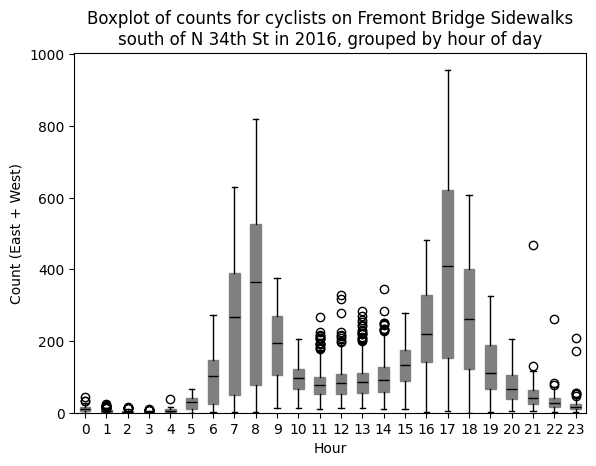

In [12]:
# color properties; https://stackoverflow.com/questions/39297093/change-the-facecolor-of-boxplot-in-pandas
color_props = {
    "boxes": "gray",
    "whiskers": "k",
    "medians": "k",
    "caps": "k"
}
ax = df_2016.boxplot(by='hour', column='total', grid=False, 
                color=color_props,
                patch_artist=True)
ax.set_ylim(0, None)  # set bottom of y-axis to 0
ax.set_xlabel('Hour')
ax.set_ylabel('Count (East + West)')
ax.set_title('Boxplot of counts for cyclists on Fremont Bridge Sidewalks\nsouth of N 34th St in 2016, grouped by hour of day')
plt.suptitle('')

plt.savefig('./counts_by_hour.png')
plt.show()

## 7. For the dataframe you created in 4, use python (and pandas) programming to computationally determine what is (on average) the busiest hour of the day. In a comment in the code write out the busiest hour (1pt)

In [13]:
# group by hour and find the median of the total count
df_2016[['total', 'hour']].groupby('hour').median()

,total
hour,
0,10.0
1,5.0
2,3.0
3,2.0
4,6.0
5,30.0
6,102.0
7,267.0
8,363.5


In [14]:
# group by hour and find the median of the total count
df_2016[['total', 'hour']].groupby('hour').median().idxmax()

total    17
dtype: int32

Hour 17, or 5 pm, was the busiest time of day on average for cyclists on the Fremont Bridge in 2016.

## 8. Describe your process for doing this homework. (If you used an AI assist, please tell us so here. It will not affect your grade as long as you tell us.) Answer this question by editing the README.md file. (1pt)

I built up the assignment in VSCode and referenced multiple sites for documentation of the various pandas and matplotlib functions, mainly for argument specification. I was pretty familiar with pandas prior to this assignment, so I didn't use AI for this one.